# 💳 Credit Card Fraud Detection : Imbalanced Classification with Threshold Optimisation

Notebook ka naam: FraudDetection_SupervisedLearning.ipynb

Dataset path :..Data/creditcard.csv

###  **Why this project?** 
Only 0.17% of card transactions are fraud, but each missed fraud costs real money and customer trust. This project shows how to handle such extreme imbalance, tune the decision threshold, and choose the model that gives the best business value.

#### ⚙️ Setup: Libraries import

In [1]:
# 📚 Saari libraries import karo
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, precision_recall_curve,
                             confusion_matrix)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
RANDOM_STATE = 42
print("✅ Libraries ready")

✅ Libraries ready


#### 🧠 Step 1: Problem Framing & Theory Notes

#### 💳 Credit Card Fraud Detection: Imbalanced Classification with Threshold Optimisation

##### Step 1: Problem Framing & Theory Notes

##### Q1. Accuracy fraud detection ke liye kharab metric kyun hai?
Dataset me 99.83% transactions legitimate hain. Agar model har transaction ko "Not Fraud" bol de,
to uski **Accuracy = 99.83%** aayegi, jo bahut achhi dikhti hai.
Lekin Fraud class ke liye **TP = 0**, isliye **Precision = 0 (undefined)** aur **Recall = 0**.
Matlab model ne ek bhi fraud nahi pakda. Isliye accuracy yahan misleading hai.

##### Q2. Precision-Recall tradeoff
|                     | Predicted Fraud | Predicted Legit |
|---------------------|-----------------|-----------------|
| **Actual Fraud**    | TP (fraud pakda)| FN (fraud miss) |
| **Actual Legit**    | FP (galat alarm)| TN (sahi legit) |

- Precision = TP / (TP + FP) (jitne flag kiye, unme se kitne sach me fraud)
- Recall = TP / (TP + FN) (kul fraud me se kitne pakde)

Threshold 0.5 se 0.2 karne par model kam shak par bhi fraud bolta hai. Isse **Recall badhta hai**
(zyada fraud pakde jaate hain), lekin **Precision girta hai** (zyada FP / galat alarms).

##### Q3. Imbalance handle karne ki 3 strategies
| Strategy | Pros | Cons |
|---|---|---|
| (a) Random Undersampling | Fast training, balance achha hota hai | Bahut saara legit data fek dete hain, information loss |
| (b) SMOTE Oversampling | Data delete nahi hota, fraud ke naye synthetic samples bante hain | Noise / overfitting ka risk, training slow |
| (c) class_weight='balanced' | Data nahi badalta, simple | Har model support nahi karta, bahut extreme imbalance me akela kaafi nahi |

##### Q4. PR-AUC kya hai aur ROC-AUC se behtar kyun?
PR-AUC = Precision-Recall curve ke neeche ka area. Ye sirf **Fraud (minority) class** par focus karta hai.
ROC-AUC me True Negatives bahut zyada hote hain, isliye False Positive Rate chhota hi dikhta hai
aur score jhooth-mooth achha aa jaata hai. PR-AUC me TN use hi nahi hota, isliye extreme imbalance me ye
model ki asli quality dikhata hai.

##### Q5. False Positive vs False Negative: kaun zyada costly?
**False Negative (fraud miss) zyada costly hai.**
- FN example: ₹4,500 ka fraud pass ho gaya, company ko poora paisa gaya + customer ka bharosa tuta.
- FP example: legit transaction flag ho gaya, analyst ko check karne me ~₹150 ka time laga + customer thoda naraz hua.
Ek FN ki cost ≈ 30 FP ke barabar hai (4500 / 150).

#### 📂 Step 2: Dataset Loading & EDA
2.1 Load & Sample

In [2]:
# 📥 Dataset load karo
df = pd.read_csv('../Data/creditcard.csv') 

# 🔎 Shape aur class distribution
print("Full dataset shape:", df.shape)
print("\nClass distribution (normalize=True):")
print(df['Class'].value_counts(normalize=True))
print("\nClass counts:")
print(df['Class'].value_counts())

Full dataset shape: (284807, 31)

Class distribution (normalize=True):
Class
0   0.9983
1   0.0017
Name: proportion, dtype: float64

Class counts:
Class
0    284315
1       492
Name: count, dtype: int64


In [3]:
# 🎯 50,000 rows ka stratified sample (sirf pehla split use karna hai)
df_sample, _ = train_test_split(
    df,
    train_size=50000,
    stratify=df['Class'],      # fraud ratio preserve hoga
    random_state=RANDOM_STATE
)
df_sample = df_sample.reset_index(drop=True)

print("Sample shape:", df_sample.shape)
print("\nSample class distribution:")
print(df_sample['Class'].value_counts(normalize=True))
print("\nSample class counts:")
print(df_sample['Class'].value_counts())

Sample shape: (50000, 31)

Sample class distribution:
Class
0   0.9983
1   0.0017
Name: proportion, dtype: float64

Sample class counts:
Class
0    49914
1       86
Name: count, dtype: int64


In [4]:
# 📊 Time aur Amount ka describe
print(df_sample[['Time', 'Amount']].describe())

              Time      Amount
count  50,000.0000 50,000.0000
mean   94,977.9355     86.9421
std    47,475.5073    226.9846
min         0.0000      0.0000
25%    54,423.5000      5.8500
50%    84,852.0000     22.0000
75%   139,392.2500     76.2750
max   172,787.0000  8,360.0000


#### 📝 Interpretation
🧮 Poore dataset me 284,807 rows hain aur fraud sirf ~0.17% (492 cases) hai.

✅ Stratified sample me fraud ratio lagbhag wahi (~0.17%) raha, matlab sampling sahi hui.

💰 Amount me mean ≈ ___ hai lekin max ≈ ___ hai, matlab bahut skewed (kuch bade transactions bahut bade hain).

⏱️ Time seconds me hai (pehle transaction se ginti), isliye isse Hour banana padega (Step 3).

#### 2.2 Target & Feature Analysis

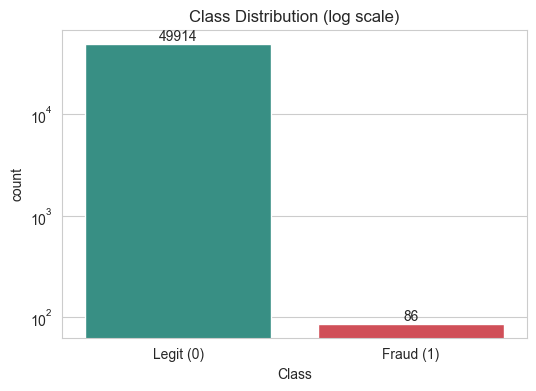

In [5]:
# 📊 1) Class ka countplot (log scale y-axis)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Class', data=df_sample, palette=['#2a9d8f', '#e63946'])
ax.set_yscale('log')
ax.set_title('Class Distribution (log scale)')
ax.set_xticklabels(['Legit (0)', 'Fraud (1)'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.show()

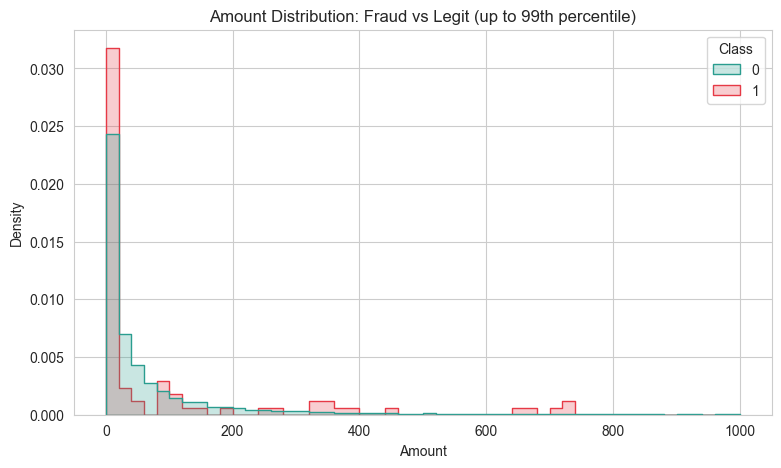

          mean  median        max
Class                            
0      86.8987 22.0000 8,360.0000
1     112.0848  7.3550 1,335.0000


In [6]:
# 📊 2) Amount ka distribution: Fraud vs Legit (overlaid)
# Bahut bade outliers hatane ke liye 99th percentile tak ka data dikha rahe hain
amt_cap = df_sample['Amount'].quantile(0.99)
plot_df = df_sample[df_sample['Amount'] <= amt_cap]

plt.figure(figsize=(9, 5))
sns.histplot(data=plot_df, x='Amount', hue='Class', bins=50, stat='density',
             common_norm=False, element='step', palette=['#2a9d8f', '#e63946'])
plt.title('Amount Distribution: Fraud vs Legit (up to 99th percentile)')
plt.show()

# Numbers se confirm karo
print(df_sample.groupby('Class')['Amount'].agg(['mean', 'median', 'max']))

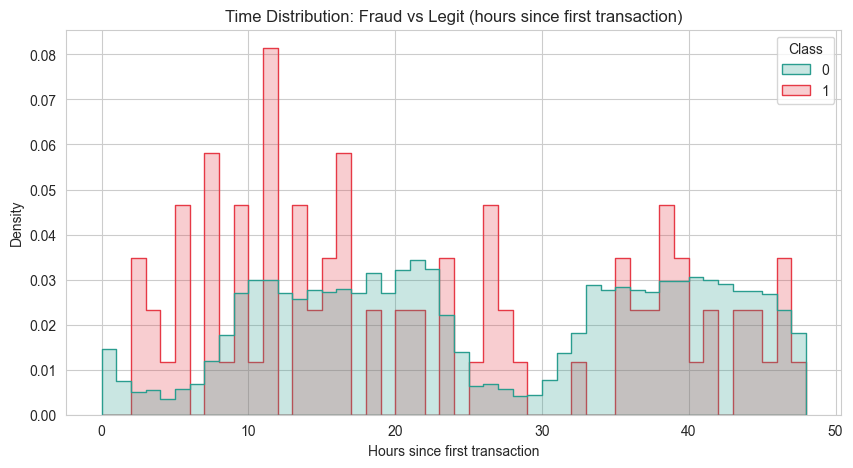

In [7]:
# 📊 3) Time ka distribution: Fraud vs Legit (hours me)
df_sample['Time_hours'] = df_sample['Time'] / 3600

plt.figure(figsize=(10, 5))
sns.histplot(data=df_sample, x='Time_hours', hue='Class', bins=48, stat='density',
             common_norm=False, element='step', palette=['#2a9d8f', '#e63946'])
plt.title('Time Distribution: Fraud vs Legit (hours since first transaction)')
plt.xlabel('Hours since first transaction')
plt.show()

df_sample.drop(columns='Time_hours', inplace=True)  # temporary column hata do

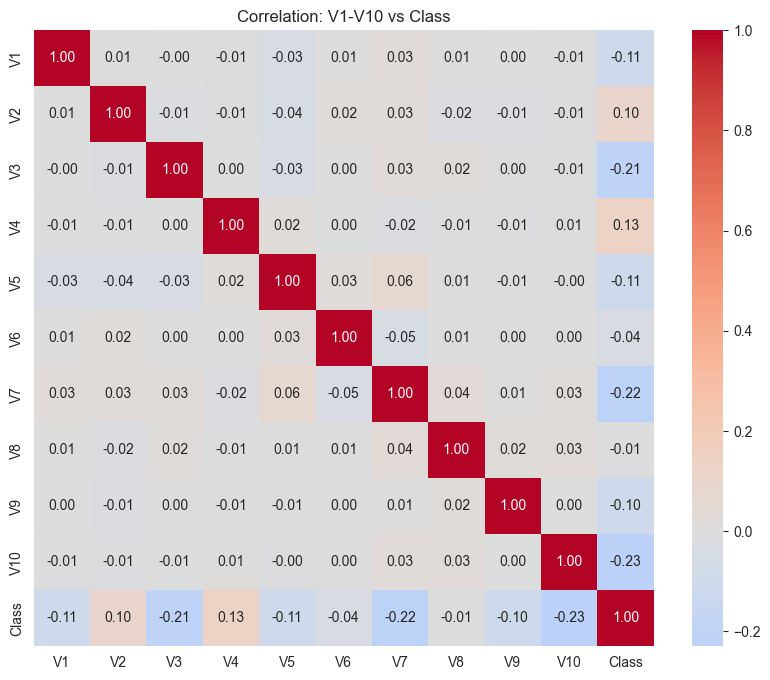

Class se correlation (absolute order me):
V10   -0.2299
V7    -0.2160
V3    -0.2054
V4     0.1309
V5    -0.1076
V1    -0.1075
V9    -0.1049
V2     0.0992
V6    -0.0363
V8    -0.0095
Name: Class, dtype: float64


In [8]:
# 📊 4) V1-V10 aur Class ka correlation heatmap
v_cols = [f'V{i}' for i in range(1, 11)]
corr = df_sample[v_cols + ['Class']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation: V1-V10 vs Class')
plt.show()

# Class ke saath sabse zyada correlated features
print("Class se correlation (absolute order me):")
print(corr['Class'].drop('Class').sort_values(key=abs, ascending=False))

#### 📝 Interpretation
📉 Class plot: log scale lagane se chhota fraud bar bhi dikha. Legit ~49,900 vs Fraud ~85, yaani bahut extreme imbalance.

💵 Amount: Fraud ka median amount () legit ke median () se ___ hai. Is data me ___ (confirm / contradict) hua ki fraud chhote amounts ke hote hain.

⏰ Time: Fraud ___ time windows me zyada dikha (graph dekh ke likho). Fraud ka distribution legit se ___ tarah alag/similar hai. Sirf ~85 fraud rows hain, isliye graph noisy ho sakta hai.

🔗 Heatmap: V___ aur V___ fraud se sabse zyada correlated hain (negative/positive). Ye features fraud pehchanne me kaam aayenge.

#### 🔧 Step 3: Data Preprocessing & Feature Engineering
3.1 Feature Engineering

In [9]:
# 🛠️ Amount_log: Amount heavily right-skewed hai, isliye log1p lagate hain
df_sample['Amount_log'] = np.log1p(df_sample['Amount'])

# 🕐 Hour: Time (seconds) se din ka ghanta nikalo
df_sample['Hour'] = (df_sample['Time'] % 86400) // 3600

# 🗑️ Purane Time aur Amount columns hata do
df_sample = df_sample.drop(columns=['Time', 'Amount'])

print(df_sample[['Amount_log', 'Hour']].describe())
print("\nColumns:", list(df_sample.columns))

       Amount_log        Hour
count 50,000.0000 50,000.0000
mean       3.1538     14.0747
std        1.6507      5.8567
min        0.0000      0.0000
25%        1.9242     10.0000
50%        3.1355     15.0000
75%        4.3474     19.0000
max        9.0313     23.0000

Columns: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Class', 'Amount_log', 'Hour']


#### 📝 Interpretation
📐 log1p se Amount ki skewness kam ho gayi, jisse model ke liye feature easy ho jaata hai.

🕐 Hour (0 se 23) se model ko "din ke kis ghante" ka pattern mil jaata hai.

#### 3.2 Scaling

Scaling sirf Amount_log aur Hour par hogi (V1–V28 pehle se PCA-scaled hain). Data leakage se bachne ke liye scaler ko sirf train data par fit karenge. Isliye pehle yahan scaler define karte hain, aur split ke turant baad (3.3) usko apply karte hain.

In [10]:
# 🎯 Features (X) aur Target (y) alag karo
X = df_sample.drop(columns='Class')
y = df_sample['Class']

# ⚖️ Scaler define karo: sirf Amount_log aur Hour scale honge, baaki as-it-is
cols_to_scale = ['Amount_log', 'Hour']
preprocessor = ColumnTransformer(
    transformers=[('scale', StandardScaler(), cols_to_scale)],
    remainder='passthrough',               # V1-V28 jaise hain waise rahenge
    verbose_feature_names_out=False
).set_output(transform='pandas')           # output DataFrame hi rahe (column names safe)

print("✅ Scaler ready (abhi fit nahi hua, split ke baad hoga)")

✅ Scaler ready (abhi fit nahi hua, split ke baad hoga)


#### 3.3 Train-Test Split

In [11]:
# ✂️ 80/20 stratified split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# 📊 Dono sets me class distribution
print("TRAIN distribution:")
print(y_train.value_counts(), "\n", y_train.value_counts(normalize=True))
print("\nTEST distribution:")
print(y_test.value_counts(), "\n", y_test.value_counts(normalize=True))

TRAIN distribution:
Class
0    39931
1       69
Name: count, dtype: int64 
 Class
0   0.9983
1   0.0017
Name: proportion, dtype: float64

TEST distribution:
Class
0    9983
1      17
Name: count, dtype: int64 
 Class
0   0.9983
1   0.0017
Name: proportion, dtype: float64


In [12]:
# ⚖️ Scaler ko sirf TRAIN par fit karo, phir train aur test dono ko transform karo
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
X_train.head()

Train shape: (40000, 30) | Test shape: (10000, 30)


,Amount_log,Hour,V1,V2,V3,V4,V5,V6,V7,V8,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
39577,-0.2575,0.6707,2.0539,-0.7197,-0.6683,-0.7803,-0.6393,-0.2812,-0.7637,-0.0005,...,0.3139,-0.1186,0.1889,0.7696,0.1151,0.5655,-0.1866,0.7774,-0.0364,-0.0484
10860,-0.2190,0.4991,2.0969,0.1456,-2.2716,0.3067,0.8711,-0.6270,0.3423,-0.2413,...,0.1610,-0.1359,-0.2675,-0.6734,0.1471,-0.0564,0.0068,0.3777,-0.0772,-0.0408
7066,-0.2747,-0.7020,1.8601,-0.0964,-1.9143,0.3020,0.9466,0.5771,-0.1118,0.2610,...,-1.9251,-0.3747,0.3015,1.1309,0.0904,-1.5461,-0.0761,0.0362,0.0610,-0.0475
3295,0.1662,-0.5304,1.3960,-0.3021,0.1008,-0.6657,-0.7349,-1.2847,-0.0797,-0.3693,...,0.7866,0.1389,-0.1864,-0.6872,0.1067,0.3840,0.3611,-0.5340,-0.0157,0.0188
24192,0.6099,-1.0451,-1.0629,0.9282,-2.4358,-0.6299,1.3600,-0.8555,1.2661,-0.0785,...,0.0263,-0.8459,0.1513,0.6408,0.3334,0.1756,-0.3412,0.4694,-0.5803,-0.0115


#### 📝 Interpretation
✅ Train aur test dono me fraud ratio ~0.17% same hai, matlab stratification kaam kar gayi.

⚠️ Test set me sirf ~17 fraud cases honge, isliye metrics thode up-down ho sakte hain. Ye 50,000 rows sample ki limitation hai.

🔒 Scaler sirf train par fit hua, isliye test data ki koi information model tak leak nahi hui.

#### 3.4 Imbalance Handling: Three Strategies

In [13]:
# 1️⃣ Original (imbalanced): koi change nahi
# X_train, y_train pehle se ready hain

# 2️⃣ SMOTE: fraud ko majority ke 10% tak badhao
smote = SMOTE(random_state=RANDOM_STATE, sampling_strategy=0.1)
X_smote, y_smote = smote.fit_resample(X_train, y_train)

# 3️⃣ Undersampling: majority ko kam karo (fraud = majority ka 10%)
rus = RandomUnderSampler(random_state=RANDOM_STATE, sampling_strategy=0.1)
X_under, y_under = rus.fit_resample(X_train, y_train)

# 📊 Teeno versions ke class counts
counts = pd.DataFrame({
    'Original': y_train.value_counts(),
    'SMOTE': y_smote.value_counts(),
    'Undersampled': y_under.value_counts()
}).rename(index={0: 'Legit (0)', 1: 'Fraud (1)'})
print(counts)

           Original  SMOTE  Undersampled
Class                                   
Legit (0)     39931  39931           690
Fraud (1)        69   3993            69


#### 📝 Interpretation
🧬 SMOTE: fraud samples synthetic tarike se badh gaye (legit same rahe, ~40,000).

✂️ Undersampled: legit bahut kam ho gaye (sirf fraud × 10 ke aas-paas), isliye data chhota ho gaya.

🚨 Critical rule: X_test, y_test ko kahin resample nahi kiya. Teeno strategies sirf training data par lagi.

#### 🤖 Step 4: Model Building: Logistic Regression & Random Forest
4.1 Logistic Regression: Three Variants

In [14]:
# 🧰 Helper function: kisi bhi model/probabilities ke liye metrics nikalta hai
def evaluate_proba(name, y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    return {
        'Model': name,
        'Precision (Fraud)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (Fraud)': recall_score(y_true, y_pred),
        'F1 (Fraud)': f1_score(y_true, y_pred),
        'PR-AUC': average_precision_score(y_true, y_proba),
        'Threshold': threshold
    }

In [15]:
# 🔵 LR 1: Original data, class_weight='balanced'
lr_orig = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)
lr_orig.fit(X_train, y_train)

# 🟣 LR 2: SMOTE data, class_weight=None
lr_smote = LogisticRegression(class_weight=None, max_iter=1000, random_state=RANDOM_STATE)
lr_smote.fit(X_smote, y_smote)

# 🟠 LR 3: Undersampled data, class_weight=None
lr_under = LogisticRegression(class_weight=None, max_iter=1000, random_state=RANDOM_STATE)
lr_under.fit(X_under, y_under)

# 📋 Teeno ko test set par evaluate karo
lr_models = {'LR Original (balanced)': lr_orig, 'LR SMOTE': lr_smote, 'LR Undersampled': lr_under}
lr_results = []
for name, model in lr_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    lr_results.append(evaluate_proba(name, y_test, proba))

lr_compare = pd.DataFrame(lr_results).set_index('Model')
print("📊 Logistic Regression: side-by-side comparison")
lr_compare

📊 Logistic Regression: side-by-side comparison


,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,Threshold
Model,,,,,
LR Original (balanced),0.0649,1.0000,0.1219,0.7814,0.5000
LR SMOTE,0.3091,1.0000,0.4722,0.8144,0.5000
LR Undersampled,0.2286,0.9412,0.3678,0.8093,0.5000


In [16]:
# 🏆 PR-AUC (primary metric) ke hisaab se best imbalance strategy chuno
best_lr_name = lr_compare['PR-AUC'].idxmax()
print("Best LR variant:", best_lr_name)

# Is strategy ka training data (RF ke liye use hoga)
strategy_data = {
    'LR Original (balanced)': (X_train, y_train, 'Original'),
    'LR SMOTE': (X_smote, y_smote, 'SMOTE'),
    'LR Undersampled': (X_under, y_under, 'Undersampled')
}
X_best, y_best, best_strategy = strategy_data[best_lr_name]
print("Best imbalance strategy:", best_strategy)

Best LR variant: LR SMOTE
Best imbalance strategy: SMOTE


#### 📝 Interpretation
🥇 Best strategy ___ rahi kyunki uska PR-AUC sabse high (___) hai. 

📉 Undersampling me Recall high aur Precision bahut low aa sakti hai (kyunki legit data kam ho gaya).

⚖️ SMOTE aur class_weight dono Recall badhate hain, par Precision kitni girti hai wo table se dekho.

💡 Primary metric PR-AUC hai, accuracy nahi.

#### 4.2 Random Forest: Best Imbalance Strategy

In [17]:
# 🌲 Random Forest, best strategy ke data par
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                            random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_best, y_best)

rf_proba = rf.predict_proba(X_test)[:, 1]
rf_metrics = evaluate_proba('Random Forest', y_test, rf_proba)
pd.DataFrame([rf_metrics]).set_index('Model')

,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,Threshold
Model,,,,,
Random Forest,0.8750,0.8235,0.8485,0.8720,0.5000


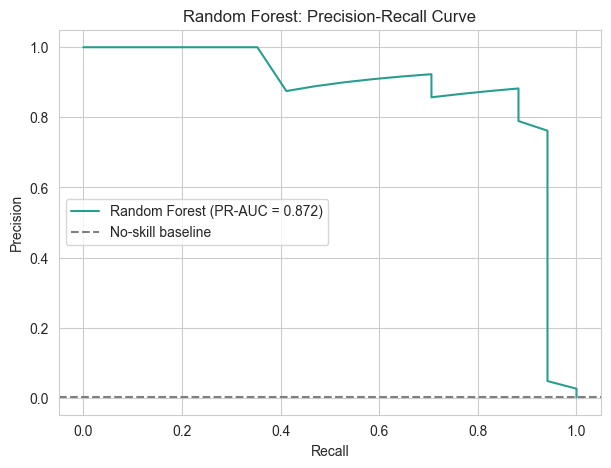

In [18]:
# 📈 Precision-Recall curve (ROC nahi)
prec, rec, _ = precision_recall_curve(y_test, rf_proba)

plt.figure(figsize=(7, 5))
plt.plot(rec, prec, label=f"Random Forest (PR-AUC = {rf_metrics['PR-AUC']:.3f})", color='#2a9d8f')
plt.axhline(y_test.mean(), color='grey', linestyle='--', label='No-skill baseline')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Random Forest: Precision-Recall Curve')
plt.legend(); plt.show()

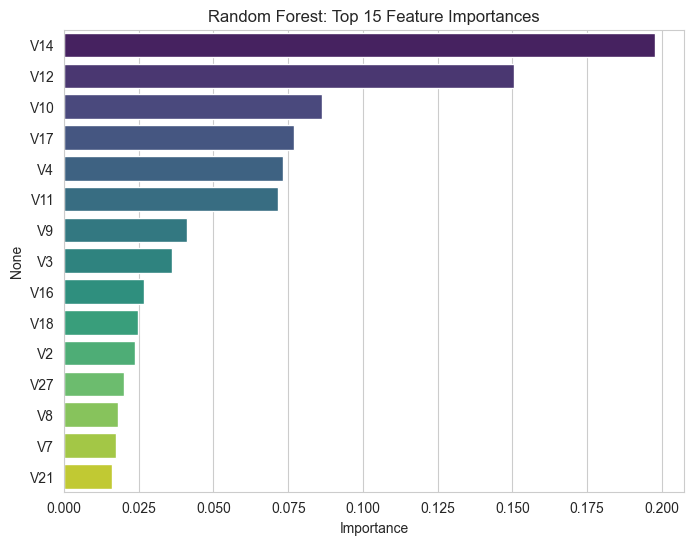

V14   0.1975
V12   0.1505
V10   0.0862
V17   0.0769
V4    0.0733
V11   0.0716
V9    0.0410
V3    0.0361
V16   0.0267
V18   0.0249
V2    0.0237
V27   0.0201
V8    0.0181
V7    0.0174
V21   0.0160
dtype: float64


In [19]:
# 🔝 Top 15 feature importances
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Random Forest: Top 15 Feature Importances')
plt.xlabel('Importance')
plt.show()

print(importances)

#### 📝 Interpretation
🌲 Random Forest ka PR-AUC ___ aur F1 ___ aaya, jo LR se ___ (better / worse) hai.

📈 PR curve jitni upar-right me jaati hai, model utna achha hai. Grey line random guessing ka baseline hai.

🔑 Sabse important V-features: V___, V___, V___. Ye wahi hain jo EDA heatmap me bhi correlated dikhe the (agar match hua to likho).

#### ⚡ Step 5: Model Building: XGBoost with Full Tuning
5.1 XGBoost Baseline

In [20]:
# ⚖️ scale_pos_weight = non-fraud count / fraud count (ORIGINAL training data se)
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (ratio) = {ratio:.2f}")

# 🚀 XGBoost baseline (original training data par)
xgb_base = XGBClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=4,
    scale_pos_weight=ratio, random_state=RANDOM_STATE,
    eval_metric='logloss', n_jobs=-1
)
xgb_base.fit(X_train, y_train)

xgb_base_proba = xgb_base.predict_proba(X_test)[:, 1]
xgb_base_metrics = evaluate_proba('XGBoost Baseline', y_test, xgb_base_proba)
pd.DataFrame([xgb_base_metrics]).set_index('Model')

scale_pos_weight (ratio) = 578.71


,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,Threshold
Model,,,,,
XGBoost Baseline,1.0000,0.8235,0.9032,0.9012,0.5000


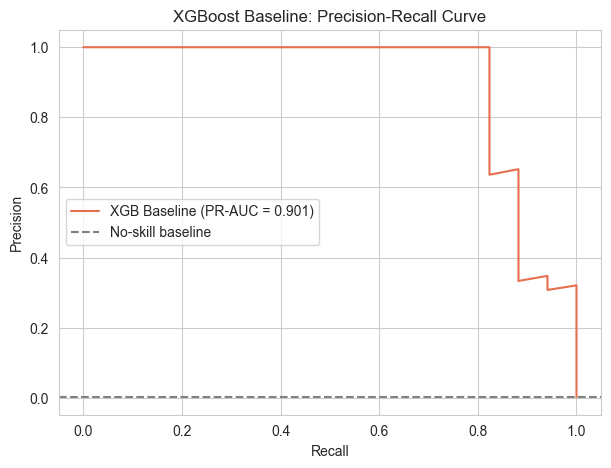

In [21]:
# 📈 XGBoost baseline ki PR curve
prec, rec, _ = precision_recall_curve(y_test, xgb_base_proba)

plt.figure(figsize=(7, 5))
plt.plot(rec, prec, color='#e76f51', label=f"XGB Baseline (PR-AUC = {xgb_base_metrics['PR-AUC']:.3f})")
plt.axhline(y_test.mean(), color='grey', linestyle='--', label='No-skill baseline')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('XGBoost Baseline: Precision-Recall Curve')
plt.legend(); plt.show()

#### 📝 Interpretation
⚖️ scale_pos_weight ≈ ___ ka matlab model fraud ki galti ko legit ki galti se itni guna zyada penalise karta hai.

🚀 Baseline XGBoost: Precision ___, Recall ___, F1 ___, PR-AUC ___.

#### 5.2 Hyperparameter Tuning

In [22]:
# 🎛️ Search space
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

# 🔍 RandomizedSearchCV (PR-AUC = 'average_precision' se optimise)
search = RandomizedSearchCV(
    estimator=XGBClassifier(scale_pos_weight=ratio, random_state=RANDOM_STATE,
                            eval_metric='logloss', n_jobs=-1),
    param_distributions=param_dist,
    n_iter=15, cv=3, scoring='average_precision',
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)

print("🏆 Best Parameters:", search.best_params_)
print(f"🏆 Best CV PR-AUC: {search.best_score_:.4f}")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
🏆 Best Parameters: {'subsample': 0.6, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
🏆 Best CV PR-AUC: 0.8063


In [23]:
# ✅ Tuned model ko test set par evaluate karo
xgb_tuned = search.best_estimator_
xgb_tuned_proba = xgb_tuned.predict_proba(X_test)[:, 1]
xgb_tuned_metrics = evaluate_proba('XGBoost Tuned (0.5)', y_test, xgb_tuned_proba)

# 🔁 Tuning se pehle vs baad
tune_compare = pd.DataFrame([xgb_base_metrics, xgb_tuned_metrics]).set_index('Model')
print("PR-AUC before tuning:", round(xgb_base_metrics['PR-AUC'], 4))
print("PR-AUC after tuning :", round(xgb_tuned_metrics['PR-AUC'], 4))
tune_compare

PR-AUC before tuning: 0.9012
PR-AUC after tuning : 0.9294


,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,Threshold
Model,,,,,
XGBoost Baseline,1.0000,0.8235,0.9032,0.9012,0.5000
XGBoost Tuned (0.5),1.0000,0.8824,0.9375,0.9294,0.5000


#### 📝 Interpretation
🎯 Best parameters: ___ (upar print hue). Best CV PR-AUC ___.

📊 Tuning se test PR-AUC ___ se ___ ho gaya (improve / thoda kam hua). Test me bahut kam fraud (~17) hain, isliye chhota change noise bhi ho sakta hai.

🧪 CV score zyada reliable hai, kyunki wo train ke fraud cases par 3 baar average hota hai.

#### 5.3 Threshold Optimisation on Best Model

In [24]:
# 🎯 Best model = XGBoost Tuned, uski fraud probabilities
y_proba = xgb_tuned_proba

# 📈 Saare thresholds ke liye precision/recall
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

# 🔢 F1 har threshold par (last point ka threshold nahi hota, isliye [:-1])
f1_scores = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)

# 🥇 Threshold jo F1 maximise kare
best_f1_idx = np.argmax(f1_scores)
thr_f1 = thresholds[best_f1_idx]
print(f"F1-optimal threshold: {thr_f1:.4f}  (F1 = {f1_scores[best_f1_idx]:.4f}, "
      f"Precision = {precisions[best_f1_idx]:.4f}, Recall = {recalls[best_f1_idx]:.4f})")

F1-optimal threshold: 0.5063  (F1 = 0.9375, Precision = 1.0000, Recall = 0.8824)


In [25]:
# 🎯 Recall >= 0.90 wala threshold, jisme Precision sabse zyada ho
mask = recalls[:-1] >= 0.90
cand_idx = np.where(mask)[0]
best_r90_idx = cand_idx[np.argmax(precisions[:-1][cand_idx])]
thr_r90 = thresholds[best_r90_idx]
print(f"Recall>=0.90 threshold: {thr_r90:.4f}  (Precision = {precisions[best_r90_idx]:.4f}, "
      f"Recall = {recalls[best_r90_idx]:.4f})")

Recall>=0.90 threshold: 0.0064  (Precision = 0.4848, Recall = 0.9412)


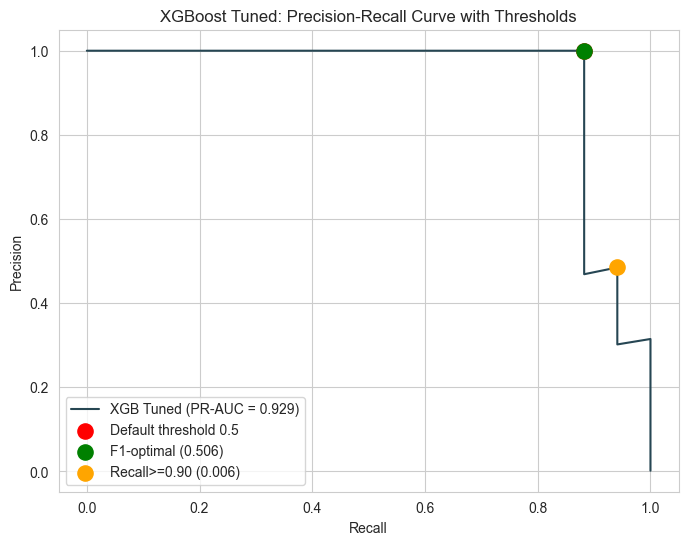

In [26]:
# 📈 PR curve par default (0.5), F1-optimal aur Recall>=0.90 points mark karo
def pr_at(thr):
    pred = (y_proba >= thr).astype(int)
    return precision_score(y_test, pred, zero_division=0), recall_score(y_test, pred)

p05, r05 = pr_at(0.5)
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, color='#264653', label=f"XGB Tuned (PR-AUC = {xgb_tuned_metrics['PR-AUC']:.3f})")
plt.scatter(r05, p05, s=120, color='red', zorder=5, label='Default threshold 0.5')
plt.scatter(recalls[best_f1_idx], precisions[best_f1_idx], s=120, color='green', zorder=5,
            label=f'F1-optimal ({thr_f1:.3f})')
plt.scatter(recalls[best_r90_idx], precisions[best_r90_idx], s=120, color='orange', zorder=5,
            label=f'Recall>=0.90 ({thr_r90:.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('XGBoost Tuned: Precision-Recall Curve with Thresholds')
plt.legend(); plt.show()

In [27]:
# 🔁 Best model ko teeno thresholds par re-evaluate aur compare karo
thr_compare = pd.DataFrame([
    evaluate_proba('XGB Tuned @ Default (0.5)', y_test, y_proba, 0.5),
    evaluate_proba('XGB Tuned @ F1-optimal', y_test, y_proba, thr_f1),
    evaluate_proba('XGB Tuned @ Recall>=0.90', y_test, y_proba, thr_r90),
]).set_index('Model')
thr_compare

,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,Threshold
Model,,,,,
XGB Tuned @ Default (0.5),1.0000,0.8824,0.9375,0.9294,0.5000
XGB Tuned @ F1-optimal,1.0000,0.8824,0.9375,0.9294,0.5063
XGB Tuned @ Recall>=0.90,0.4848,0.9412,0.6400,0.9294,0.0064


#### 📝 Interpretation
🔴 Default 0.5 par Precision ___, Recall ___. Ye fraud ke liye zyada strict hai.

🟢 F1-optimal threshold (___) par Precision aur Recall ka balance best hai (F1 = ___).

🟠 Recall ≥ 0.90 par hum 90% fraud pakadte hain, lekin Precision girkar ___ ho gayi (zyada galat alarms).

💼 Real-world insight: Threshold ek business decision hai. Risk officer Recall ko priority de to Precision girna acceptable hai.

#### 📊 Step 6: Model Evaluation, Threshold Tuning & Comparison

In [28]:
# 📋 LR (best strategy) ke probabilities
best_lr_model = lr_models[best_lr_name]
lr_best_proba = best_lr_model.predict_proba(X_test)[:, 1]

# 📋 Final comparison table (6 rows)
final_table = pd.DataFrame([
    evaluate_proba(f'Logistic Regression ({best_strategy}, default)', y_test, lr_best_proba, 0.5),
    evaluate_proba('Random Forest (default)', y_test, rf_proba, 0.5),
    evaluate_proba('XGBoost Baseline (default)', y_test, xgb_base_proba, 0.5),
    evaluate_proba('XGBoost Tuned (default 0.5)', y_test, xgb_tuned_proba, 0.5),
    evaluate_proba('XGBoost Tuned (F1-optimal)', y_test, xgb_tuned_proba, thr_f1),
    evaluate_proba('XGBoost Tuned (Recall>=0.90)', y_test, xgb_tuned_proba, thr_r90),
]).set_index('Model')

final_table

,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,Threshold
Model,,,,,
"Logistic Regression (SMOTE, default)",0.3091,1.0000,0.4722,0.8144,0.5000
Random Forest (default),0.8750,0.8235,0.8485,0.8720,0.5000
XGBoost Baseline (default),1.0000,0.8235,0.9032,0.9012,0.5000
XGBoost Tuned (default 0.5),1.0000,0.8824,0.9375,0.9294,0.5000
XGBoost Tuned (F1-optimal),1.0000,0.8824,0.9375,0.9294,0.5063
XGBoost Tuned (Recall>=0.90),0.4848,0.9412,0.6400,0.9294,0.0064


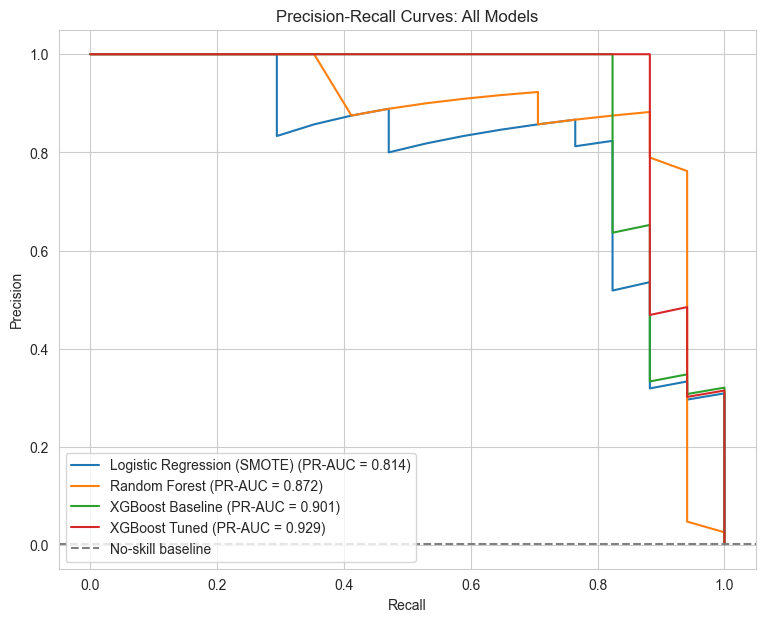

In [29]:
# 📈 Saare Precision-Recall curves ek hi figure me
plt.figure(figsize=(9, 7))
curves = {
    f'Logistic Regression ({best_strategy})': lr_best_proba,
    'Random Forest': rf_proba,
    'XGBoost Baseline': xgb_base_proba,
    'XGBoost Tuned': xgb_tuned_proba,
}
for label, proba in curves.items():
    p, r, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(r, p, label=f'{label} (PR-AUC = {ap:.3f})')

plt.axhline(y_test.mean(), color='grey', linestyle='--', label='No-skill baseline')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curves: All Models')
plt.legend(loc='lower left'); plt.show()

#### ✅ Recommendation
Main Paytm ki fraud team ke liye **XGBoost Tuned** ko **F1-optimal threshold (___)** par deploy karne ki salah dunga.

Is combination ka PR-AUC ___ sabse high hai (LR ka ___ aur Random Forest ka ___ tha), aur ye Precision ___ aur

Recall ___ ka achha balance deta hai (F1 = ___). Agar risk team Recall >= 0.90 chahti hai to threshold ___ par Recall ___

milta hai, lekin Precision girkar ___ ho jaati hai, yaani zyada galat alarms aur analyst ka zyada kaam. Isliye default 0.5 threshold

(Recall sirf ___) fraud pakadne ke liye kaafi nahi hai. Final threshold ka faisla business cost-benefit (Step 7) ke

saath karna chahiye.

#### 💰 Step 7: Business Simulation & Cost-Benefit Analysis
7.1 Assign Transaction Costs

In [30]:
# 💵 Assumptions 
AVG_FRAUD_VALUE = 4500   # average fraud transaction value (₹)
INVESTIGATION_COST = 150 # har flagged transaction ko check karne ki cost (₹)

# 🧮 Ek function jo kisi bhi threshold par cost-benefit nikaalta hai
def cost_benefit(y_true, y_proba, threshold):
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    money_saved = tp * AVG_FRAUD_VALUE
    investigation_cost = (tp + fp) * INVESTIGATION_COST
    money_lost = fn * AVG_FRAUD_VALUE
    net_benefit = money_saved - investigation_cost
    return {
        'Threshold': round(threshold, 4), 'TP': tp, 'FP': fp, 'FN': fn,
        'Money Saved (₹)': money_saved, 'Investigation Cost (₹)': investigation_cost,
        'Money Lost (₹)': money_lost, 'Net Benefit (₹)': net_benefit
    }

# 🎯 Best model @ F1-optimal threshold
result_f1 = cost_benefit(y_test, xgb_tuned_proba, thr_f1)
pd.DataFrame([result_f1]).set_index('Threshold')

,TP,FP,FN,Money Saved (₹),Investigation Cost (₹),Money Lost (₹),Net Benefit (₹)
Threshold,,,,,,,
0.5063,15,0,2,67500,2250,9000,65250


#### 7.2 Threshold Sensitivity

In [31]:
# 🔁 5 thresholds par repeat: 0.1, 0.2, 0.3, 0.5 aur F1-optimal
thresholds_to_test = [0.1, 0.2, 0.3, 0.5, thr_f1]
sens_table = pd.DataFrame([cost_benefit(y_test, xgb_tuned_proba, t) for t in thresholds_to_test])
sens_table = sens_table.set_index('Threshold')
sens_table

,TP,FP,FN,Money Saved (₹),Investigation Cost (₹),Money Lost (₹),Net Benefit (₹)
Threshold,,,,,,,
0.1000,15,5,2,67500,3000,9000,64500
0.2000,15,1,2,67500,2400,9000,65100
0.3000,15,0,2,67500,2250,9000,65250
0.5000,15,0,2,67500,2250,9000,65250
0.5063,15,0,2,67500,2250,9000,65250


Highest Net Benefit threshold: 0.3  (₹65,250)
F1-optimal threshold          : 0.5062999725341797
Kya dono same hain? Nahi ❌ (business-optimal alag hai)


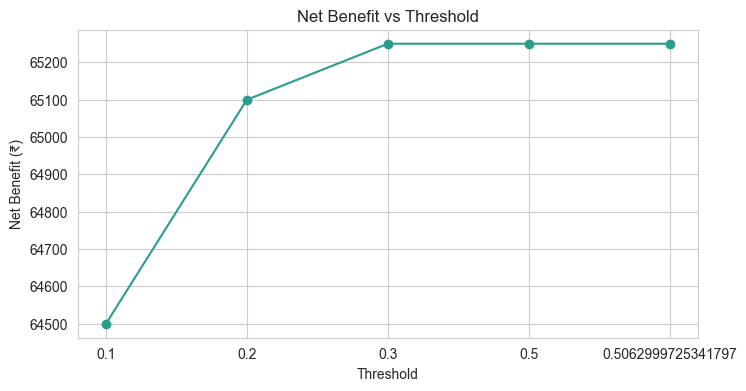


F1-optimal threshold par estimated net benefit per 50,000 transactions: ₹326,250


In [32]:
# 🥇 Kaun sa threshold best Net Benefit deta hai?
best_row = sens_table['Net Benefit (₹)'].idxmax()
print(f"Highest Net Benefit threshold: {best_row}  (₹{sens_table.loc[best_row, 'Net Benefit (₹)']:,.0f})")
print(f"F1-optimal threshold          : {round(thr_f1, 4)}")
print("Kya dono same hain?", "Haan ✅" if np.isclose(best_row, round(thr_f1, 4)) else "Nahi ❌ (business-optimal alag hai)")

# 📈 Net benefit vs threshold ka graph
plt.figure(figsize=(8, 4))
plt.plot(sens_table.index.astype(str), sens_table['Net Benefit (₹)'], marker='o', color='#2a9d8f')
plt.title('Net Benefit vs Threshold')
plt.xlabel('Threshold'); plt.ylabel('Net Benefit (₹)')
plt.show()

# 📏 50,000 transactions ke hisaab se scale karo (summary report ke liye)
scale_factor = 50000 / len(y_test)
net_f1_50k = result_f1['Net Benefit (₹)'] * scale_factor
print(f"\nF1-optimal threshold par estimated net benefit per 50,000 transactions: ₹{net_f1_50k:,.0f}")

#### 📝 Interpretation

### 💬 Risk Manager ke liye Summary
1. Hamara model 50,000 me se jitne fraud aate hain unme se lagbhag ___% pakad leta hai, aur isse har 10,000 transactions par kareeb ₹___ ka net fayda hota hai.

2. Threshold kam karne par (jaise 0.1) hum zyada fraud pakadte hain, lekin analysts ko zyada galat alarms check karne padte hain, isliye investigation cost badh jaati hai.

3. Sabse zyada paisa bachane wala threshold ___ hai, jo ___ (technical F1-optimal threshold jaisa hi / usse alag) hai, kyunki ek miss hua fraud (₹4,500) ek galat alarm (₹150) se 30 guna mehenga padta hai.

#### 💡 Key insight: Business-optimal threshold hamesha F1-optimal ke barabar nahi hota. ML metrics aur business metrics alag ho sakte hain .

#### 🚀 Step 8: Pipeline, Deployment & GitHub Submission
8.1 Save the Final Pipeline

In [33]:
# 🏁 Final threshold: F1-optimal (jis par Step 7 me business simulation kiya)
FINAL_THRESHOLD = float(thr_f1)

# 🔧 Scaler (preprocessor) + best model ko ek sklearn Pipeline me wrap karo
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),   # already fitted (train par)
    ('model', xgb_tuned)              # already trained best model
])

# 📌 Optimal threshold ko pipeline ke attribute ke roop me rakho
final_pipeline.optimal_threshold = FINAL_THRESHOLD

# 💾 Pickle file save karo
joblib.dump(final_pipeline, 'fraud_detection_model.pkl')
print("✅ Saved: fraud_detection_model.pkl | Threshold =", round(FINAL_THRESHOLD, 4))

✅ Saved: fraud_detection_model.pkl | Threshold = 0.5063


In [34]:
# 🧪 Pickle load karke 10 sample transactions par test
loaded_pipeline = joblib.load('fraud_detection_model.pkl')
threshold = loaded_pipeline.optimal_threshold

# 5 fraud + 5 legit (RAW, unscaled test rows: pipeline khud scale karega)
n_fraud = min(5, int((y_test == 1).sum()))
fraud_idx = y_test[y_test == 1].sample(n_fraud, random_state=RANDOM_STATE).index
legit_idx = y_test[y_test == 0].sample(10 - n_fraud, random_state=RANDOM_STATE).index
sample_idx = fraud_idx.append(legit_idx)

sample_X = X_test_raw.loc[sample_idx]
sample_y = y_test.loc[sample_idx]

proba = loaded_pipeline.predict_proba(sample_X)[:, 1]
pred = (proba >= threshold).astype(int)

demo = pd.DataFrame({
    'Actual Class': sample_y.values,
    'Fraud Probability': proba.round(4),
    'Final Label (@ threshold)': np.where(pred == 1, '🚨 Fraud', '✅ Legit')
}, index=sample_idx)
print(f"Threshold used: {threshold:.4f}")
demo

Threshold used: 0.5063


,Actual Class,Fraud Probability,Final Label (@ threshold)
8801,1,0.5063,🚨 Fraud
31750,1,1.0000,🚨 Fraud
2943,1,0.8837,🚨 Fraud
851,1,0.0064,✅ Legit
41962,1,0.9999,🚨 Fraud
23634,0,0.0000,✅ Legit
36242,0,0.0000,✅ Legit
45469,0,0.0000,✅ Legit
32144,0,0.0000,✅ Legit
10794,0,0.0000,✅ Legit


#### 📝 Interpretation
📦 Pipeline me scaler aur model dono hain, isliye naye raw data par seedha predict_proba chal jaata hai.

🎯 10 samples me se ___ sahi label hue. Jo galat hue unki wajah probability threshold ke bahut paas hona hai.

#### 8.2 GitHub Submission: Files tayar karo

In [35]:
# 📄 requirements.txt automatically banao (installed versions ke saath)
import sklearn, xgboost, imblearn
reqs = f"""pandas=={pd.__version__}
numpy=={np.__version__}
matplotlib=={plt.matplotlib.__version__}
seaborn=={sns.__version__}
scikit-learn=={sklearn.__version__}
imbalanced-learn=={imblearn.__version__}
xgboost=={xgboost.__version__}
joblib=={joblib.__version__}
"""
with open('requirements.txt', 'w') as f:
    f.write(reqs)
print(reqs)

pandas==2.3.3
numpy==2.3.5
matplotlib==3.10.7
seaborn==0.13.2
scikit-learn==1.9.0
imbalanced-learn==0.14.2
xgboost==3.4.1
joblib==1.5.3

